# 03 - Cell-type annotation
Label the 22 scVI/Leiden clusters from marker-gene evidence. Annotation is done manually at the cluster level (two layers: `cell_type` and a coarser `lineage`), with a stated confidence per cluster, rather than by an automated classifier, so every label can be traced back to specific genes.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt
sc.settings.set_figure_params(dpi=100, frameon=False)
FIG = "../results/figures/"
adata = sc.read_h5ad("../data/processed/cd45_integrated.h5ad")
adata.obsm["X_umap"] = adata.obsm["X_umap_scvi"]
adata

AnnData object with n_obs × n_vars = 87486 × 3000
    obs: 'gsm', 'patient', 'sample', 'timepoint', 'biopsy_site', 'best_overall_response', 'response', 'tls', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'outlier', 'n_genes', 'doublet_score', 'predicted_doublet', '_scvi_batch', '_scvi_labels', 'leiden'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'patient_colors', 'response_colors', 'sample_colors', 'scrublet', 'timepoint_colors', 'umap'
    obsm: 'X_scVI', 'X_umap', 'X_umap_scvi', 'X_umap_unintegrated'
    obsp: 'connectivities', 'distances'
    layers: 'counts', None (.X)

## 1. Differential expression per cluster (Wilcoxon, <=1500 cells per cluster)

In [2]:
rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.where(adata.obs.leiden == c)[0], min(1500, (adata.obs.leiden == c).sum()), replace=False)
                      for c in adata.obs.leiden.cat.categories])
raw = adata.raw.to_adata()[idx].copy(); raw.obs = adata.obs.iloc[idx]
sc.tl.rank_genes_groups(raw, "leiden", method="wilcoxon", pts=True)
markers = sc.get.rank_genes_groups_df(raw, None)
markers = markers[(markers.logfoldchanges > 0.5) & (markers.pvals_adj < 0.01)]
markers.to_csv("../results/tables/cluster_markers.csv", index=False)
for c in adata.obs.leiden.cat.categories:
    print(f"[{c:>2}] n={(adata.obs.leiden == c).sum():<5}", ", ".join(markers[markers.group == c].sort_values("scores", ascending=False).names[:10]))

[ 0] n=2075  HSPA1A, DNAJB1, HSPA1B, HSP90AA1, HSPE1, HSPH1, HSPA8, UBC, HSP90AB1, CACYBP
[ 1] n=305   SSR4, MZB1, IGHG1, IGKC, DERL3, JCHAIN, FKBP11, XBP1, IGHG3, SEC11C
[ 2] n=6960  IL32, FOXP3, HLA-A, B2M, SPOCK2, CTLA4, TIGIT, S100A4, BATF, IL2RG
[ 3] n=1112  MALAT1, MTRNR2L12, PTPRC, RNF213, MT-ATP6, HLA-A, HLA-E, HLA-B, MT-CO2, MT-CO1
[ 4] n=8758  CCL5, CD8A, NKG7, GZMK, CD8B, CTSW, CST7, GZMA, IL32, KLRK1
[ 5] n=10006 CD52, IL7R, CD3E, IL32, B2M, CD2, CD69, TMSB4X, RPL41, RPS25
[ 6] n=7139  RPS12, RPL32, RPL30, RPL13, RPL11, RPS14, RPS3A, RPS3, RPL34, RPS15A
[ 7] n=1453  ITM2A, NR3C1, SRGN, CXCL13, FKBP5, LAT, FYB1, CORO1B, EEF1A1, TIGIT
[ 8] n=15266 CCL5, CD8A, NKG7, CST7, CD8B, GZMA, CTSW, CD3E, GZMK, HLA-A
[ 9] n=9762  FTL, CST3, HLA-DRB1, HLA-DRA, TYROBP, FCER1G, HLA-DPA1, AIF1, C1QA, MS4A6A
[10] n=237   GSTP1, LSP1, CD74, HLA-DPB1, HLA-DQA1, HLA-DRA, HLA-DPA1, ALDH2, TXN, CD83
[11] n=814   PLD4, JCHAIN, IRF8, LILRA4, IRF7, SEC61B, GZMB, IL3RA, PLAC8, CCDC50
[12] n=2819  IFI

## 2. Annotation
Evidence for each call is the marker genes named in the table. Confidence reflects how unambiguous the markers are, and how many cells support the call.

In [3]:
annot = {
 # cluster: (cell_type, lineage, confidence, key evidence)
 "0":  ("T cell (stress response)",            "T/NK",       "medium", "heat-shock genes (HSPA1A, DNAJB1) on a CD3E+ IL7R+ GZMK+ background"),
 "1":  ("Plasma cell",                         "B/plasma",   "high",   "MZB1, JCHAIN, IGKC, IGHG1, XBP1"),
 "2":  ("Regulatory T cell",                   "T/NK",       "high",   "FOXP3, CTLA4, TIGIT, BATF, IL2RG"),
 "3":  ("Low-quality lymphocyte",              "Unresolved", "low",    "MALAT1, mitochondrial genes; mixed CD8/CD4 signal"),
 "4":  ("CD8 T (GZMK+ effector memory)",       "T/NK",       "high",   "CD8A, CD8B, GZMK, CCL5, NKG7"),
 "5":  ("CD4 T (IL7R+ memory)",                "T/NK",       "medium", "IL7R, CD3E, CD69, low CD8A"),
 "6":  ("CD4 T (naive/central memory)",        "T/NK",       "medium", "CCR7, TCF7, IL7R; ribosomal-high"),
 "7":  ("CD4 T (CXCL13+ PD-1+, Tph-like)",     "T/NK",       "medium", "CXCL13, PDCD1, TOX, TIGIT, ITM2A; CD8A low"),
 "8":  ("CD8 T (cytotoxic, exhausted-like)",   "T/NK",       "high",   "CD8A, NKG7, GZMK, GZMB, LAG3, HAVCR2, PDCD1, TOX"),
 "9":  ("Macrophage (C1Q+)",                   "Myeloid",    "high",   "C1QA, APOE, CD68, CD163, MS4A6A, HLA-DR"),
 "10": ("Mature DC (LAMP3+ CCR7+)",            "Myeloid",    "high",   "LAMP3, CCR7, CD83, HLA-DQA1"),
 "11": ("Plasmacytoid DC",                     "Myeloid",    "high",   "LILRA4, IRF7, IRF8, PLD4, IL3RA, GZMB"),
 "12": ("Classical monocyte",                  "Myeloid",    "high",   "LYZ, FCN1, S100A8/9, CD14"),
 "13": ("Inflammatory myeloid (tiny)",         "Myeloid",    "low",    "IL1B, CXCL1/2/3, SPP1; 11 cells, one patient"),
 "14": ("Proliferating T cell",                "T/NK",       "high",   "MKI67, STMN1, TUBB, CD3E, CD8A"),
 "15": ("Melanoma cell",                       "Non-immune", "high",   "PMEL, MLANA, TYR, GPNMB; PTPRC low"),
 "16": ("B cell",                              "B/plasma",   "high",   "MS4A1, CD79A, CD79B, BANK1"),
 "17": ("B cell (germinal-centre-like)",       "B/plasma",   "medium", "MS4A1, TCL1A, MEF2B, LRMP, POU2AF1"),
 "18": ("Fibroblast",                          "Non-immune", "high",   "COL1A1, SPARC, FN1, BGN; PTPRC low"),
 "19": ("NK cell",                             "T/NK",       "high",   "GNLY, KLRD1, NKG7, XCL1/2; CD3E low"),
 "20": ("CD8 T (GZMK+ HAVCR2+, small)",        "T/NK",       "low",    "GZMK, CD8B, HAVCR2, TIGIT; 51 cells"),
 "21": ("Endothelial cell",                    "Non-immune", "high",   "PECAM1, VWF, PLVAP, RAMP2; PTPRC absent"),
}
tab = pd.DataFrame(annot, index=["cell_type", "lineage", "confidence", "evidence"]).T
tab["cells"] = adata.obs.leiden.value_counts().reindex(tab.index).values
tab.to_csv("../results/tables/cluster_annotation.csv")
adata.obs["cell_type"] = adata.obs.leiden.map(tab.cell_type).astype("category")
adata.obs["lineage"] = adata.obs.leiden.map(tab.lineage).astype("category")
tab[["cell_type", "lineage", "confidence", "cells"]]

,cell_type,lineage,confidence,cells
0,T cell (stress response),T/NK,medium,2075
1,Plasma cell,B/plasma,high,305
2,Regulatory T cell,T/NK,high,6960
3,Low-quality lymphocyte,Unresolved,low,1112
4,CD8 T (GZMK+ effector memory),T/NK,high,8758
5,CD4 T (IL7R+ memory),T/NK,medium,10006
6,CD4 T (naive/central memory),T/NK,medium,7139
7,"CD4 T (CXCL13+ PD-1+, Tph-like)",T/NK,medium,1453
8,"CD8 T (cytotoxic, exhausted-like)",T/NK,high,15266
9,Macrophage (C1Q+),Myeloid,high,9762


## 3. Marker evidence

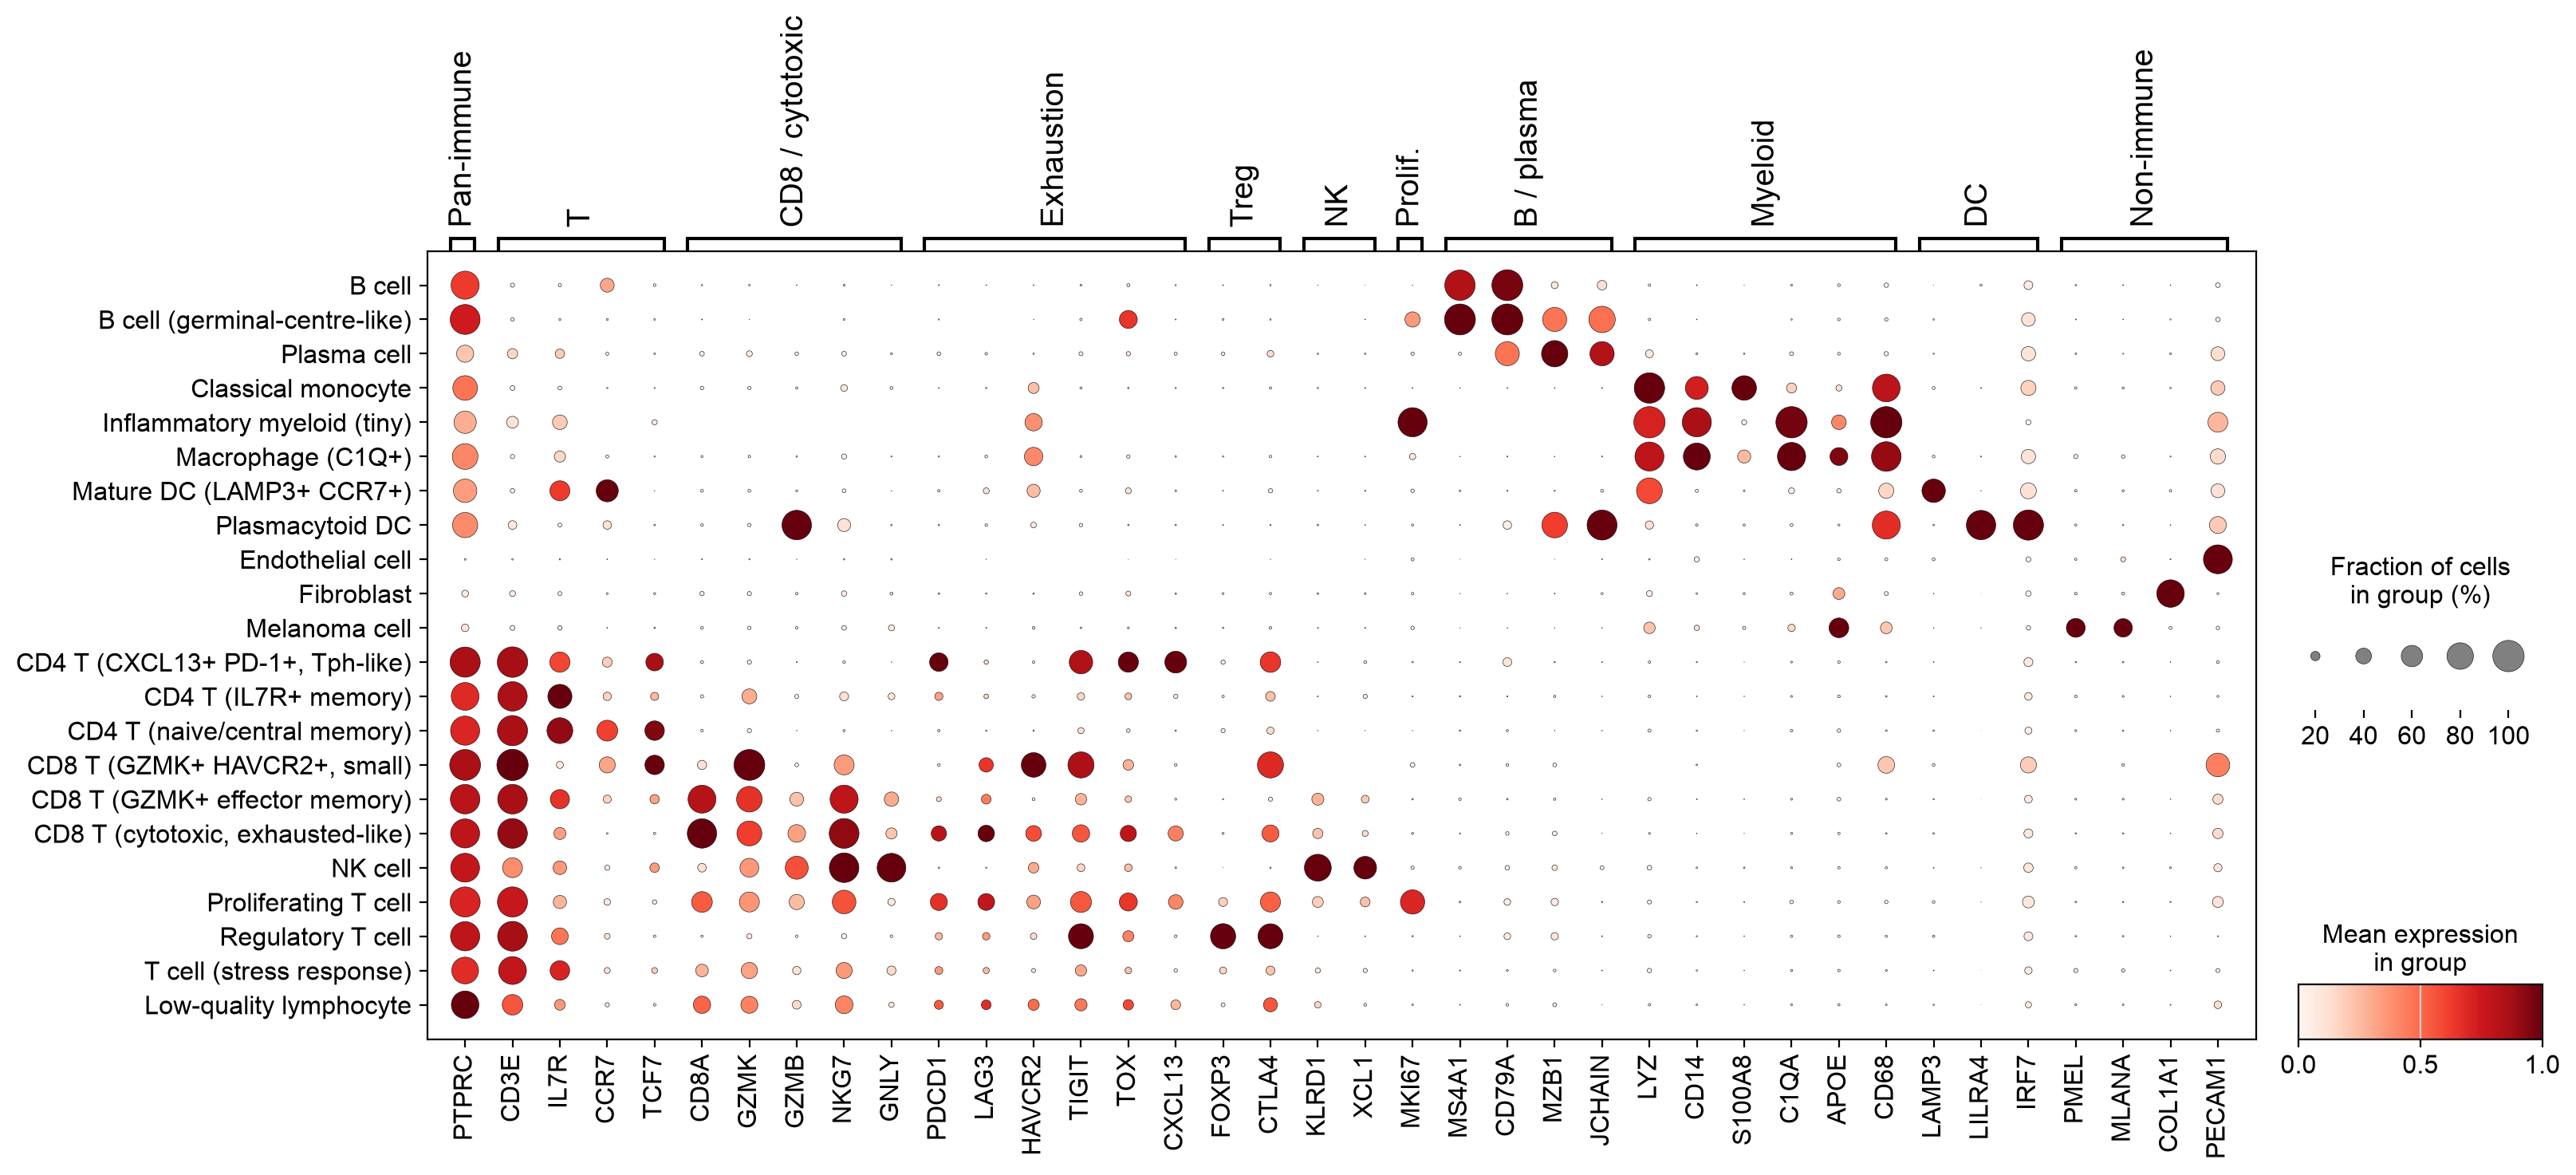

In [4]:
order = tab.sort_values(["lineage", "cell_type"]).cell_type.unique().tolist()
adata.obs["cell_type"] = adata.obs["cell_type"].cat.reorder_categories(order)
genes = {"Pan-immune": ["PTPRC"], "T": ["CD3E", "IL7R", "CCR7", "TCF7"], "CD8 / cytotoxic": ["CD8A", "GZMK", "GZMB", "NKG7", "GNLY"],
         "Exhaustion": ["PDCD1", "LAG3", "HAVCR2", "TIGIT", "TOX", "CXCL13"], "Treg": ["FOXP3", "CTLA4"], "NK": ["KLRD1", "XCL1"],
         "Prolif.": ["MKI67"], "B / plasma": ["MS4A1", "CD79A", "MZB1", "JCHAIN"], "Myeloid": ["LYZ", "CD14", "S100A8", "C1QA", "APOE", "CD68"],
         "DC": ["LAMP3", "LILRA4", "IRF7"], "Non-immune": ["PMEL", "MLANA", "COL1A1", "PECAM1"]}
sc.pl.dotplot(adata, genes, groupby="cell_type", use_raw=True, standard_scale="var", show=False, figsize=(17, 6.5))
plt.savefig(FIG + "03_marker_dotplot.png", dpi=150, bbox_inches="tight")

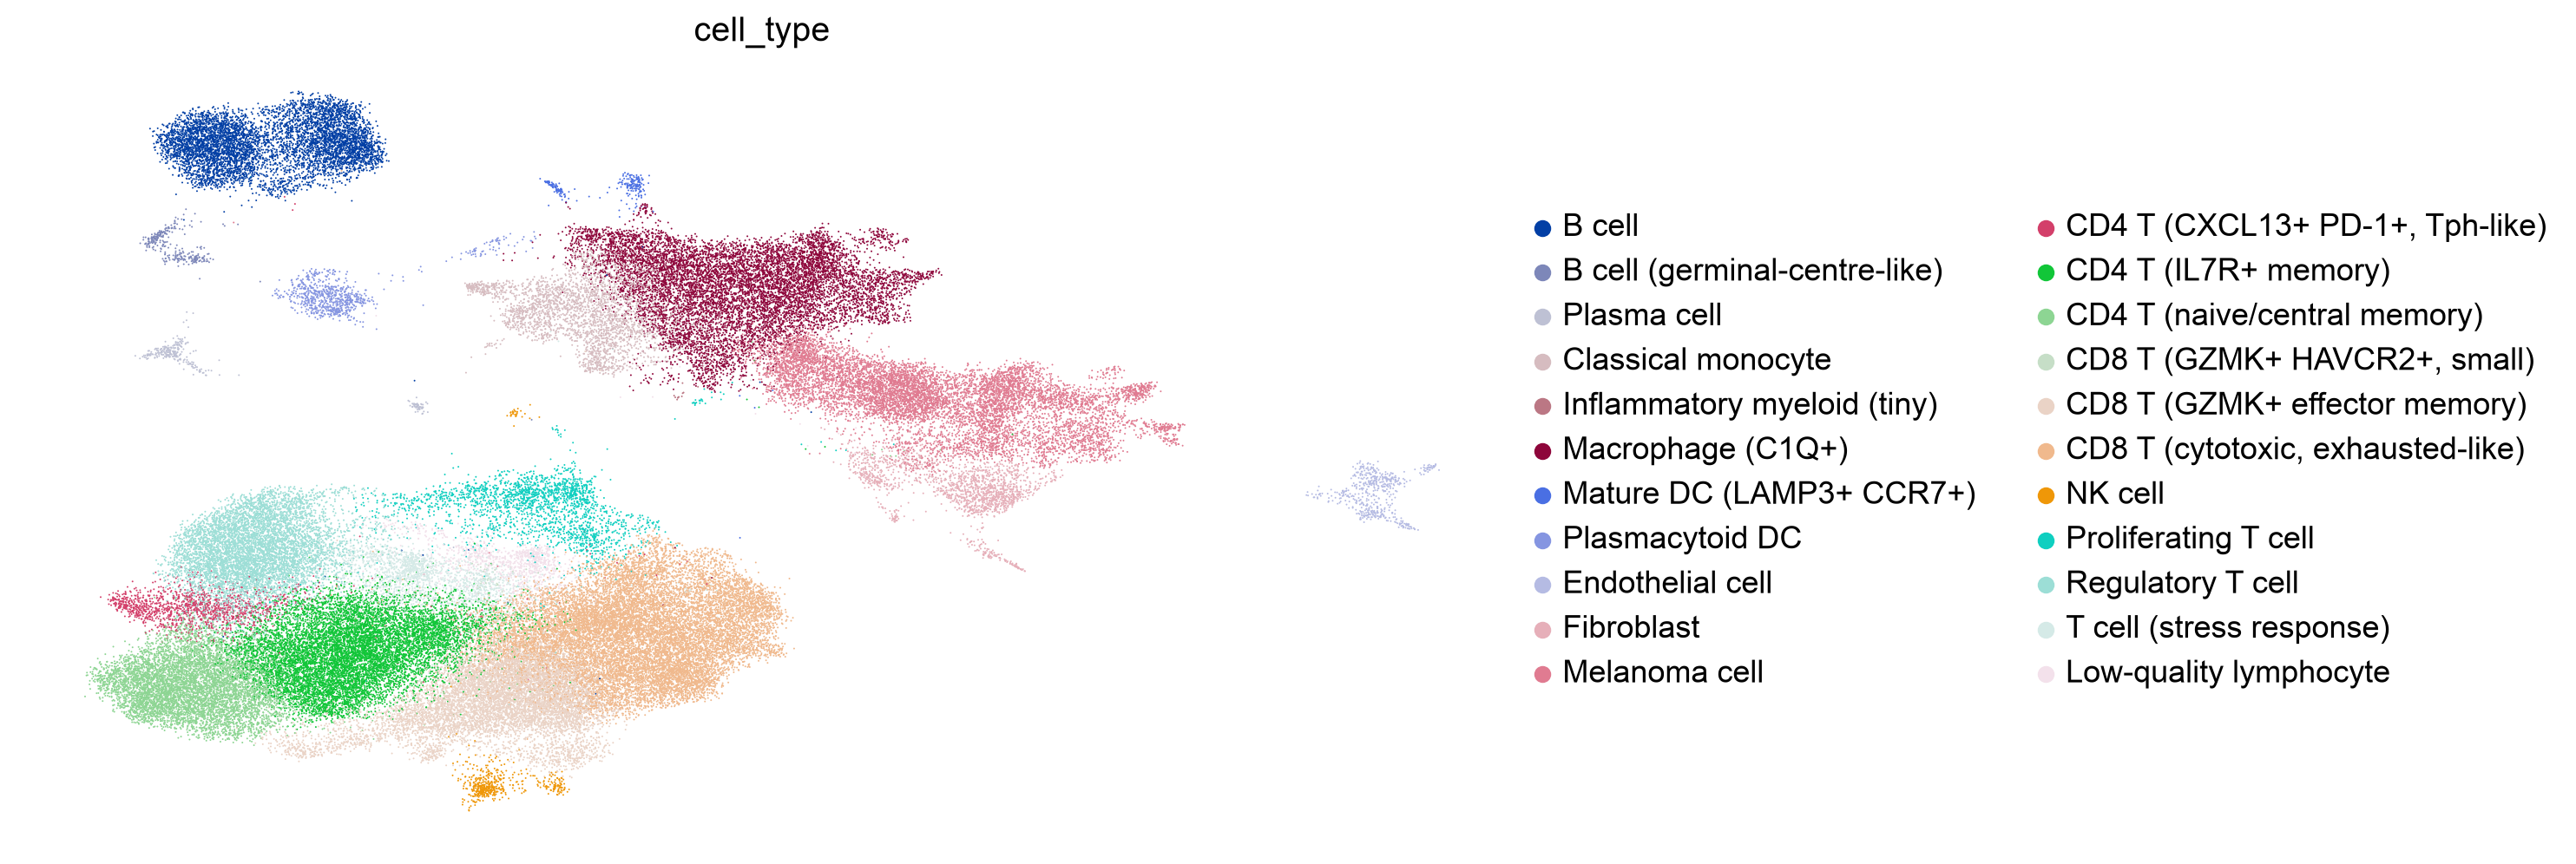

In [5]:
sc.pl.umap(adata, color="cell_type", size=2, show=False, legend_loc="right margin", frameon=False)
plt.gcf().set_size_inches(11, 6)
plt.savefig(FIG + "03_umap_cell_types.png", dpi=150, bbox_inches="tight")

## 4. Where do the non-immune cells come from?
Melanoma cells, fibroblasts and endothelial cells should be absent from a CD45+-sorted library. If they come from a few libraries, composition comparisons must be restricted to immune cells.

In [6]:
ni = adata.obs[adata.obs.lineage == "Non-immune"]
print("Non-immune cells:", len(ni), f"({len(ni)/adata.n_obs:.1%} of all cells)")
share = pd.crosstab(adata.obs["sample"], adata.obs["lineage"] == "Non-immune", normalize="index")[True].mul(100).round(1)
share[share > 1].sort_values(ascending=False).to_frame("% non-immune")

Non-immune cells: 11377 (13.0% of all cells)


,% non-immune
sample,
patient5_T30,96.4
patient6_T30,68.0
patient8_T30,25.8
patient1_T30,20.4
patient7_T30,15.0
patient12_T0,2.8
patient10_T01,2.0
patient4_T0,1.9
patient10_T02,1.5


In [7]:
adata.write_h5ad("../data/processed/cd45_annotated.h5ad", compression="gzip")
print(adata.obs.lineage.value_counts())

lineage
T/NK          54511
Myeloid       13643
Non-immune    11377
B/plasma       6843
Unresolved     1112
Name: count, dtype: int64
